**MAMOONA IQBAL**

*C2C LAB - Afternoon 1*

Course: AI/ML

**Assignment 51 — Week 5, Day 1**

Topic: Machine Learning

Implement linear regression in Python with scikit-learn.

Problem:
Predict exam score of student from study hours

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

In [2]:
#Create Data Frame:
data = {
    "StudyHours": [
        1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
        1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 11
    ],
    "ExamScore": [
        15, 20, 32, 35, 48, 52, 65, 70, 82, 88,
        18, 27, 30, 43, 50, 60, 68, 78, 85, 95
    ]
}

df = pd.DataFrame(data)

In [3]:
print(df.head())

   StudyHours  ExamScore
0         1.0         15
1         2.0         20
2         3.0         32
3         4.0         35
4         5.0         48


In [5]:
#Explore Data:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   StudyHours  20 non-null     float64
 1   ExamScore   20 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 452.0 bytes
None


In [6]:
#Clean data:
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Check data types and basic statistics
print("\nData types:")
print(df.dtypes)


Missing values:
StudyHours    0
ExamScore     0
dtype: int64

Duplicate rows: 0

Data types:
StudyHours    float64
ExamScore       int64
dtype: object


In [7]:
print("\nStatistical summary:")
print(df.describe())


Statistical summary:
       StudyHours  ExamScore
count   20.000000   20.00000
mean     5.775000   53.05000
std      3.002083   25.18244
min      1.000000   15.00000
25%      3.375000   31.50000
50%      5.750000   51.00000
75%      8.125000   72.00000
max     11.000000   95.00000


In [8]:
#Features and Target Value
X = df[["StudyHours"]]  # Input must be 2D
y = df["ExamScore"]     # Target is 1D

print("FEATURES (X):")
print(X.head())

print("TARGET (y):")
print(y.head())


FEATURES (X):
   StudyHours
0         1.0
1         2.0
2         3.0
3         4.0
4         5.0
TARGET (y):
0    15
1    20
2    32
3    35
4    48
Name: ExamScore, dtype: int64


In [9]:
#Split data:
X_train, X_test, y_train, y_test = train_test_split(X,y,
    test_size=0.20,
    random_state=42
)

print("Train Test SPLIT:")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Train Test SPLIT:
Training rows: 16
Testing rows: 4


In [11]:
#FEATURE SCALING:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

In [12]:
#Train the model:
model.fit(X_train, y_train)
print("Mode is Traind.")

Mode is Traind.


In [13]:
#REGRESSION EQUATION:
scaler = model.named_steps["scaler"]
regressor = model.named_steps["regressor"]

# Convert coefficients back to the original StudyHours scale
slope = regressor.coef_[0] / scaler.scale_[0]
intercept = regressor.intercept_ - slope * scaler.mean_[0]

print("REGRESSION EQUATION:")
print(f"Intercept: {intercept:.2f}")
print(f"Slope: {slope:.2f}")

REGRESSION EQUATION:
Intercept: 4.63
Slope: 8.35


In [15]:
#Predictions on Test data:

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "StudyHours": X_test["StudyHours"].values,
    "ActualScore": y_test.values,
    "PredictedScore": y_pred
})
results["Error"] = (
    results["ActualScore"] - results["PredictedScore"]
)
results["AbsoluteError"] = results["Error"].abs()

print("TEST PREDICTIONS:")
print(results.round(2).sort_values("StudyHours"))



TEST PREDICTIONS:
   StudyHours  ActualScore  PredictedScore  Error  AbsoluteError
0         1.0           15           12.98   2.02           2.02
3         2.0           20           21.33  -1.33           1.33
2         6.5           60           58.89   1.11           1.11
1         8.5           78           75.59   2.41           2.41


In [16]:
#Evaluate the Model:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Evaluate the Model:")
print(f"MAE  (Mean Absolute Error): {mae:.2f}")
print(f"MSE  (Mean Squared Error): {mse:.2f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.2f}")
print(f"R²   (R-squared Score): {r2:.4f}")

Evaluate the Model:
MAE  (Mean Absolute Error): 1.72
MSE  (Mean Squared Error): 3.22
RMSE (Root Mean Squared Error): 1.80
R²   (R-squared Score): 0.9954


In [18]:
# Predict for a new student
new_student = pd.DataFrame({"StudyHours": [7]})
new_prediction = model.predict(new_student)

print("Predicted score for 7 study hours:",
    round(new_prediction[0], 2))

Predicted score for 7 study hours: 63.07


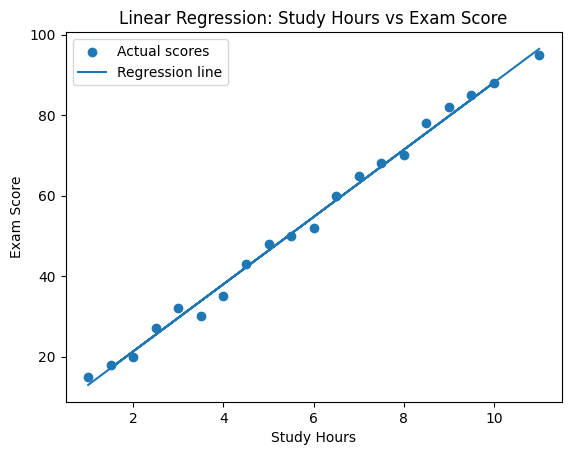

In [19]:
# Visualize the regression line
plt.scatter(X, y, label="Actual scores")
plt.plot(X, model.predict(X), label="Regression line")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Linear Regression: Study Hours vs Exam Score")
plt.legend()
plt.show()

**Assignment 52 — Week 5, Day 3**

**Topic: Machine Learning**

Perform Logistic Regression.


Problem: Predict student Pass / Fail

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report,ConfusionMatrixDisplay,)

In [22]:
# DATAFRAME:
data = {
    "StudyHours": [
        1, 2, 1.5, 3, 2.5, 4, 3.5, 5, 4.5, 6,
        5.5, 7, 6.5, 8, 7.5, 9, 8.5, 10, 9.5, 11,
        2, 3, 4, 5, 6, 7, 8, 9, 10, 11
    ],
    "Attendance": [
        40, 45, 50, 55, 48, 60, 58, 65, 62, 70,
        68, 75, 72, 80, 78, 85, 82, 90, 88, 95,
        35, 50, 55, 60, 65, 70, 75, 80, 85, 90
    ],
    "Pass": [
        0, 0, 0, 0, 0, 0, 0, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        0, 0, 0, 0, 1, 1, 1, 1, 1, 1
    ]
}

In [23]:
df = pd.DataFrame(data)

df.head(10)

,StudyHours,Attendance,Pass
0,1.0,40,0
1,2.0,45,0
2,1.5,50,0
3,3.0,55,0
4,2.5,48,0
5,4.0,60,0
6,3.5,58,0
7,5.0,65,1
8,4.5,62,0
9,6.0,70,1


In [24]:
#Explore Data:
print("Data information:")
df.info()

Data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   StudyHours  30 non-null     float64
 1   Attendance  30 non-null     int64  
 2   Pass        30 non-null     int64  
dtypes: float64(1), int64(2)
memory usage: 852.0 bytes


In [25]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values:
StudyHours    0
Attendance    0
Pass          0
dtype: int64
Duplicate rows: 0


In [26]:
# Remove duplicate and incomplete rows
df = df.drop_duplicates().copy()
df = df.dropna(subset=["StudyHours", "Attendance", "Pass"])

print("Target class counts:")
print(df["Pass"].value_counts())


Target class counts:
Pass
1    18
0    12
Name: count, dtype: int64


In [27]:
#Features and Target:

X = df[["StudyHours", "Attendance"]]
y = df["Pass"].astype(int)

In [28]:
#Train test Split data:
X_train, X_test, y_train, y_test = train_test_split(X,y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 22
Testing rows: 8


In [29]:
#Scaling and training the Logistic Regression Model:

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model is Trained.")

Model is Trained.


In [30]:
#Predictions:

y_pred = model.predict(X_test)

# Probability of class 1 (Pass)
y_prob = model.predict_proba(X_test)[:, 1]

results = X_test.copy()
results["Actual"] = y_test
results["Predicted"] = y_pred
results["PassProbability"] = y_prob.round(3)

print("TEST PREDICTIONS:")
print(results.sort_index())

TEST PREDICTIONS:
    StudyHours  Attendance  Actual  Predicted  PassProbability
3          3.0          55       0          0            0.196
6          3.5          58       0          0            0.273
8          4.5          62       0          0            0.436
9          6.0          70       1          1            0.726
10         5.5          68       1          1            0.649
12         6.5          72       1          1            0.791
13         8.0          80       1          1            0.929
15         9.0          85       1          1            0.966


In [31]:
# Predict for a new student:
new_student = pd.DataFrame({
    "StudyHours": [6],
    "Attendance": [75]
})

prediction = model.predict(new_student)[0]
probability = model.predict_proba(new_student)[0, 1]

In [32]:
print("\nNew student prediction:",
      "Pass" if prediction == 1 else "Fail")
print("Predicted class:", prediction)
print("Result:", "PASS" if prediction == 1 else "FAIL")
print(f"Probability of passing: {probability:.2%}")


New student prediction: Pass
Predicted class: 1
Result: PASS
Probability of passing: 79.51%


In [33]:
# Model Evaluation:
accuracy = accuracy_score(y_test, y_pred)
confusion_matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Model Evaluation:")
print(f"Accuracy: {accuracy:.3f}")

print("Confusion Matrix:")
print(confusion_matrix)


Model Evaluation:
Accuracy: 1.000
Confusion Matrix:
[[3 0]
 [0 5]]


In [34]:
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fail", "Pass"],
    zero_division=0
))

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         3
        Pass       1.00      1.00      1.00         5

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



<Figure size 1000x1000 with 0 Axes>

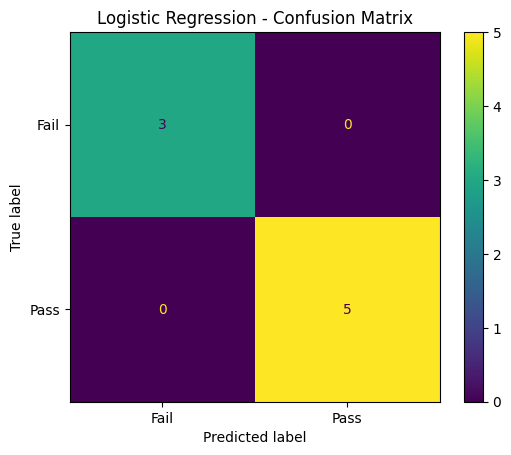

In [35]:
#confusion matrix:

plt.figure(figsize=(10, 10))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix,
    display_labels=["Fail", "Pass"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")

plt.show()